In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

La estructura de un edificio industrial se hormigona en las actividades con `hormigon_m3` > 0 del cuadro adjunto (prelaciones, duraciones en semanas, duraciones mínimas alcanzables y coste unitario de reducción `ucr` en k€ por semana). La obra se ejecuta en invierno. Hay dos hormigones que cumplen la resistencia característica y la clase de exposición del pliego: **A**, con cemento CEM I, y **B**, con cemento CEM III/A de bajo contenido en clínker, que adquiere la resistencia más despacio y, en estas condiciones, alarga **una semana** cada actividad de hormigonado (desencofrado y puesta en carga).

In [4]:
#| tbl-cap: "Cuadro de datos del enunciado"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration, cap_duration, ucr, hormigon_m3
    ('A'     , '---'      , 6       , 3           , 5  , 240        ),
    ('B'     , '---'      , 3       , 2           , 1  , 0          ),
    ('C'     , '---'      , 7       , 7           , 0  , 0          ),
    ('D'     , 'A,B'      , 5       , 2           , 1  , 0          ),
    ('E'     , 'C,D'      , 1       , 1           , 0  , 0          ),
    ('F'     , 'C,D'      , 4       , 3           , 1  , 0          ),
    ('G'     , 'F'        , 5       , 3           , 4  , 390        ),
    ('H'     , 'G'        , 1       , 1           , 0  , 510        ),
    ('I'     , 'E'        , 4       , 2           , 3  , 550        ),
], columns=['activity', 'predecessor', 'duration', 'cap_duration', 'ucr', 'hormigon_m3']).set_index('activity')
datos_enunciado

,predecessor,duration,cap_duration,ucr,hormigon_m3
activity,,,,,
A,---,6,3,5,240
B,---,3,2,1,0
C,---,7,7,0,0
D,"A,B",5,2,1,0
E,"C,D",1,1,0,0
F,"C,D",4,3,1,0
G,F,5,3,4,390
H,G,1,1,0,510
I,E,4,2,3,550


In [5]:
#| tbl-cap: "Los dos hormigones"
#| label: tbl-hormigones
hormigones = pd.DataFrame([
#  hormigon                                  , precio (€/m³), emisiones (t CO₂/m³), semanas más por actividad de hormigonado
    ('A: CEM I (hormigón habitual)'            , 95           , 0.3                 , 0                                       ),
    ('B: CEM III/A (bajo contenido en clínker)', 103          , 0.21                , 1                                       ),
], columns=['hormigon', 'precio (€/m³)', 'emisiones (t CO₂/m³)', 'semanas más por actividad de hormigonado']).set_index('hormigon')
hormigones

,precio (€/m³),emisiones (t CO₂/m³),semanas más por actividad de hormigonado
hormigon,,,
A: CEM I (hormigón habitual),95,0.30,0
B: CEM III/A (bajo contenido en clínker),103,0.21,1


El coste indirecto de la obra (medios auxiliares, instalaciones, equipo técnico) es de 8 k€ por semana de duración. La organización aplica un precio sombra del carbono de 150 €/t a sus decisiones.

> **De: Director de producción**
> Hormigón de siempre, CEM I: el otro tarda una semana más en desencofrar y nos come la ruta crítica, y nunca hemos trabajado con CEM III. El carbono del cemento es del cementero, no nuestro, y el pliego no dice nada del cemento.

## Criterio de referencia

Las preguntas del bloque **B** se responden aplicando los criterios siguientes, tomados de la lección 20 (redactados por el curso; cada uno remite a la fuente de la que procede, que no se reproduce). La respuesta se justifica citando el criterio y la fuente, no con una opinión.

- **S15 — Prestaciones, no costumbre.** El pliego especifica el material por prestaciones (resistencia característica, clase de exposición, durabilidad) y plazos; entre materiales que las cumplen se decide por el coste total con la externalidad (S2) y por el ciclo de vida (S3), y el efecto de cada uno en el cronograma (plazos de curado, de suministro) se calcula, no se supone. «Siempre se ha hecho así» no es un criterio del pliego, y una huella menor no autoriza a aceptar un material que no cumple las prestaciones. *(cf. Código Estructural (RD 470/2021), tipificación del hormigón y anejo 4 (cementos); LCSP art. 126 (prescripciones técnicas por rendimiento o exigencias funcionales); PMBOK 8 §3.7.3 (dominio de recursos: materiales y prácticas sostenibles).)*
- **S2 — Externalidad internalizada.** Cuando la organización ha fijado un precio para una externalidad (precio sombra del carbono, canon, tasa), toda decisión de planificación —comprimir, comprar, diseñar— se compara por el coste total: coste del proyecto más el valor de la externalidad a ese precio. Con el precio fijado, la alternativa correcta es la de menor coste total, y comprar compensaciones a un precio inferior no cambia la cuenta. *(cf. PMBOK 8 §3.7 (estrategias para abordar las externalidades); LCSP art. 148.2 (externalidades medioambientales monetizables); precio sombra del carbono del BEI.)*
- **S6 — Alcances de las emisiones.** Las emisiones de un proyecto se clasifican por quién controla la fuente: alcance 1, combustión en fuentes propias o controladas (maquinaria y vehículos propios, generadores); alcance 2, electricidad comprada; alcance 3, el resto de la cadena (subcontratas, transporte ajeno, materiales comprados, viajes). A qué alcance pertenece cada fuente tiene respuesta determinada, y el alcance 3 no deja de contar por ser ajeno. *(cf. GHG Protocol, estándar corporativo; UNE-EN ISO 14064-1; registro de huella de carbono del MITECO (RD 163/2014).)*
- **S1 — Jerarquía de respuesta a los impactos (pirámide de sostenibilidad).** Ante un impacto negativo del proyecto las estrategias se ordenan de menos a más deseable: compensar o contrarrestar el daño, restaurarlo, minimizarlo y evitarlo. Compensar cuando se podía minimizar o evitar es quedarse en el escalón más bajo; clasificar una propuesta en su escalón es una pregunta con respuesta única. *(cf. PMBOK 8, principio «integrar la sostenibilidad en todas las áreas del proyecto» (§3.7, figura 3-7).)*
- **Norma o dato de referencia — el hormigón estructural se tipifica por prestaciones (resistencia característica a 28 días, consistencia, tamaño máximo del árido y clase de exposición) y el cemento se elige entre los admitidos para la aplicación; los cementos con adiciones (escoria, cenizas, puzolanas) tienen menos clínker y menos emisiones por tonelada y adquieren la resistencia más despacio, lo que alarga los plazos de desencofrado y puesta en carga, sobre todo en tiempo frío** *(Código Estructural (RD 470/2021), tipificación del hormigón y anejo 4; UNE-EN 197-1.)*

Responda a las preguntas: A (cálculo), B (criterio) y C (deliberación).

In [6]:
pregunta_1 = "1. (A) Calcule el coste del hormigón y las emisiones de cada opción, y la duración del proyecto con cada una (con B, una semana más en cada actividad de hormigonado). ¿Cuántas semanas se retrasa el proyecto con B y cuánto cuestan al coste indirecto?  "
pregunta_2 = "2. (A) Recupere con Ackoff-Sasieni las semanas de retraso de B acortando otras actividades (las de hormigonado no pueden bajar de su mínimo más la semana de curado) y obtenga el coste de la compresión. Compare el coste monetario y el coste total al precio sombra de las tres opciones: A, B con retraso y B comprimido.  "
pregunta_3 = "3. (B) Según los criterios de referencia, ¿puede rechazarse B «porque siempre se ha usado CEM I»? ¿Qué opción es la correcta al precio sombra? ¿De quién son las emisiones del cemento (alcance)? ¿En qué escalón de la pirámide queda cada opción?  "
pregunta_4 = "4. (C) ¿Qué propone al director de producción y a la dirección facultativa? Aplique la rúbrica de la lección.  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. (A) Calcule el coste del hormigón y las emisiones de cada opción, y la duración del proyecto con cada una (con B, una semana más en cada actividad de hormigonado). ¿Cuántas semanas se retrasa el proyecto con B y cuánto cuestan al coste indirecto?  

2. (A) Recupere con Ackoff-Sasieni las semanas de retraso de B acortando otras actividades (las de hormigonado no pueden bajar de su mínimo más la semana de curado) y obtenga el coste de la compresión. Compare el coste monetario y el coste total al precio sombra de las tres opciones: A, B con retraso y B comprimido.  

3. (B) Según los criterios de referencia, ¿puede rechazarse B «porque siempre se ha usado CEM I»? ¿Qué opción es la correcta al precio sombra? ¿De quién son las emisiones del cemento (alcance)? ¿En qué escalón de la pirámide queda cada opción?  

4. (C) ¿Qué propone al director de producción y a la dirección facultativa? Aplique la rúbrica de la lección.  

# Resolución

In [7]:
coste_semana, precio_sombra = 8, 150
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()
calendario = proyecto.calendar(datos_proyecto['duration'])
duracion = int(proyecto.duration(datos_proyecto['duration']))
hormigonado = sorted(datos_proyecto.index[datos_proyecto['hormigon_m3'] > 0])
M = float(datos_proyecto['hormigon_m3'].sum())
duraciones_B = datos_proyecto['duration'].copy(); duraciones_B[hormigonado] += 1
minimos_B = datos_proyecto['cap_duration'].copy(); minimos_B[hormigonado] += 1
duracion_B = int(proyecto.duration(duraciones_B))
retraso = duracion_B - duracion

Cálculo de los tiempos tempranos y tardíos de los sucesos y de las holguras totales paso a paso. El primer paso muestra el grafo resuelto; a partir del siguiente se calcula desde el principio (avance con los botones):

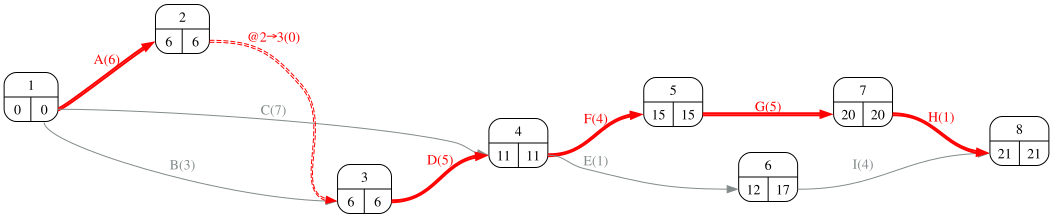

In [9]:
#| fig-cap: "Grafo PERT con el hormigón A"
#| label: fig-pert
proyecto.display_pert_pasos(datos_proyecto['duration'])

## Apartado 1

In [10]:
display(Markdown(pregunta_1))

1. (A) Calcule el coste del hormigón y las emisiones de cada opción, y la duración del proyecto con cada una (con B, una semana más en cada actividad de hormigonado). ¿Cuántas semanas se retrasa el proyecto con B y cuánto cuestan al coste indirecto?  

In [11]:
#| tbl-cap: "Coste del hormigón, emisiones y duración con cada opción"
#| label: tbl-opciones
h = hormigones.copy()
h['hormigón (k€)'] = M * h['precio (€/m³)'] / 1000
h['emisiones (t CO₂)'] = M * h['emisiones (t CO₂/m³)']
h['duración del proyecto (semanas)'] = [duracion, duracion_B]
h['retraso (semanas)'] = [0, retraso]
h['coste indirecto del retraso (k€)'] = h['retraso (semanas)'] * coste_semana
display(h.iloc[:, 3:].round(1))
camino_B = ' / '.join('–'.join(r) for r in proyecto.critical_path(duraciones_B).values())
Markdown(f'''{M:,.0f} m³ de hormigón: B cuesta {h.iloc[1, 3] - h.iloc[0, 3]:.1f} k€ más y emite **{h.iloc[0, 4] - h.iloc[1, 4]:.0f} t menos**. Con B el proyecto dura {duracion_B} semanas (ruta crítica {camino_B}): **{retraso}** semana(s) de retraso, {retraso * coste_semana} k€ de coste indirecto.''')

,hormigón (k€),emisiones (t CO₂),duración del proyecto (semanas),retraso (semanas),coste indirecto del retraso (k€)
hormigon,,,,,
A: CEM I (hormigón habitual),160.6,507.0,21,0,0
B: CEM III/A (bajo contenido en clínker),174.1,354.9,24,3,24


1,690 m³ de hormigón: B cuesta 13.5 k€ más y emite **152 t menos**. Con B el proyecto dura 24 semanas (ruta crítica A–D–F–G–H): **3** semana(s) de retraso, 24 k€ de coste indirecto.

## Apartado 2

In [12]:
display(Markdown(pregunta_2))

2. (A) Recupere con Ackoff-Sasieni las semanas de retraso de B acortando otras actividades (las de hormigonado no pueden bajar de su mínimo más la semana de curado) y obtenga el coste de la compresión. Compare el coste monetario y el coste total al precio sombra de las tres opciones: A, B con retraso y B comprimido.  

In [13]:
#| tbl-cap: "Ackoff-Sasieni sobre el plan con B para recuperar el retraso"
#| label: tbl-ackoff
tabla_c, pasos_c, duraciones_c, margen_c = proyecto.ackoff(durations=duraciones_B, min_durations=minimos_B,
                                                         costs=datos_proyecto['ucr'], reduction=retraso, report=False)
proyecto.display_ackoff_pasos(
    durations=duraciones_B,
    min_durations=minimos_B,
    costs=datos_proyecto['ucr'],
    reduction=retraso)

,A,B,C,D,E,F,G,H,I,0,1,2,3
Route_1,5.0,,,1.0,0.0,,,,3.0,18.0,17.0,16.0,15.0
Route_2,5.0,,,1.0,,1.0,4.0,0.0,,24.0,23.0,22.0,21.0
Route_3,,1.0,,1.0,0.0,,,,3.0,14.0,13.0,12.0,11.0
Route_4,,1.0,,1.0,,1.0,4.0,0.0,,20.0,19.0,18.0,17.0
Route_5,,,0.0,,0.0,,,,3.0,13.0,13.0,13.0,13.0
Route_6,,,0.0,,,1.0,4.0,0.0,,19.0,19.0,19.0,19.0
0,3.0,1.0,0.0,3.0,0.0,1.0,2.0,0.0,2.0,,,,
1,3.0,1.0,0.0,2.0,0.0,1.0,2.0,0.0,2.0,,,,
2,3.0,1.0,0.0,1.0,0.0,1.0,2.0,0.0,2.0,,,,
3,3.0,1.0,0.0,0.0,0.0,1.0,2.0,0.0,2.0,,,,


In [14]:
#| tbl-cap: "Opciones consideradas en cada paso"
#| label: tbl-ackoffPasos
detalle_ackoff(proyecto, duraciones_B, minimos_B, datos_proyecto['ucr'], pasos_c)

,duración,rutas críticas,opciones (coste),elegida,coste del paso
paso,,,,,
1,24,Route_2,F (1); D (1); G (4); A (5),D,1.0
2,23,Route_2,F (1); D (1); G (4); A (5),D,1.0
3,22,Route_2,F (1); D (1); G (4); A (5),D,1.0


In [15]:
#| tbl-cap: "Las tres opciones: coste monetario y coste total al precio sombra"
#| label: tbl-comparacion
coste_compresion = float(sum(datos_proyecto.loc[a, 'ucr'] for paso in pasos_c.values() for a in paso))
opciones = pd.DataFrame({'A': [h.iloc[0, 3], 0.0, 0.0, h.iloc[0, 4]],
                         'B con retraso': [h.iloc[1, 3], retraso * coste_semana, 0.0, h.iloc[1, 4]],
                         'B comprimido': [h.iloc[1, 3], 0.0, coste_compresion, h.iloc[1, 4]]},
                        index=['hormigón (k€)', 'coste indirecto del retraso (k€)', 'compresión (k€)', 'emisiones (t CO₂)'])
opciones.loc['coste monetario (k€)'] = opciones.iloc[:3].sum()
opciones.loc['carbono al precio sombra (k€)'] = opciones.loc['emisiones (t CO₂)'] * precio_sombra / 1000
opciones.loc['coste total (k€)'] = opciones.loc['coste monetario (k€)'] + opciones.loc['carbono al precio sombra (k€)']
display(opciones.round(1))
mejor = opciones.loc['coste total (k€)'].idxmin(); mas_barata = opciones.loc['coste monetario (k€)'].idxmin()
Markdown(f'''Recuperar las {retraso} semana(s) cuesta **{coste_compresion:.0f} k€** (pasos: ''' + '; '.join('paso ' + str(k + 1) + ': ' + ', '.join(v) for k, v in sorted(pasos_c.items())) + f'''). En dinero gana **{mas_barata}**; al precio sombra de {precio_sombra} €/t gana **{mejor}** ({opciones.loc['coste total (k€)', mejor]:.1f} k€ frente a {opciones.loc['coste total (k€)', 'A']:.1f} de A).''')

,A,B con retraso,B comprimido
hormigón (k€),160.6,174.1,174.1
coste indirecto del retraso (k€),0.0,24.0,0.0
compresión (k€),0.0,0.0,3.0
emisiones (t CO₂),507.0,354.9,354.9
coste monetario (k€),160.6,198.1,177.1
carbono al precio sombra (k€),76.0,53.2,53.2
coste total (k€),236.6,251.3,230.3


Recuperar las 3 semana(s) cuesta **3 k€** (pasos: paso 1: D; paso 2: D; paso 3: D). En dinero gana **A**; al precio sombra de 150 €/t gana **B comprimido** (230.3 k€ frente a 236.6 de A).

## Apartado 3

In [16]:
display(Markdown(pregunta_3))

3. (B) Según los criterios de referencia, ¿puede rechazarse B «porque siempre se ha usado CEM I»? ¿Qué opción es la correcta al precio sombra? ¿De quién son las emisiones del cemento (alcance)? ¿En qué escalón de la pirámide queda cada opción?  

**S15.** Los dos hormigones cumplen las prestaciones del pliego (resistencia característica y clase de exposición); el pliego, como dice el director, no fija el cemento, y «nunca hemos trabajado con CEM III» no es una prestación: B **no puede rechazarse por costumbre**. Lo que sí hay que calcular es su efecto en el cronograma (3 semana(s)), y se ha calculado. **S2.** Con el precio sombra la opción correcta es la de menor coste total: **B comprimido** (230.3 k€ frente a 236.6 de A); en dinero A es más barata (160.6 frente a 177.1 de B comprimido), y esa diferencia es exactamente lo que la política de la organización decide pagar por 152 t. **S6.** Las emisiones de fabricación del cemento son **alcance 3** del proyecto (material comprado): ser «del cementero» no las saca del inventario, igual que el acero importado. **S1.** Sustituir el cemento **minimiza** (152 t menos con la misma estructura); **evitar** sería rediseñar para necesitar menos hormigón; A más créditos sería compensar.

In [17]:
preguntas_test = [
    ('Un hormigón que cumple la resistencia característica y la clase de exposición del pliego…', ['no puede rechazarse por costumbre: se compara por coste total y ciclo de vida, con su efecto en el plazo calculado', 'puede rechazarse si el jefe de obra no lo conoce', 'sólo puede usarse si es más barato', 'sólo puede usarse en elementos no estructurales'],
     'S15: especificación por prestaciones.'),
    ('Las emisiones de fabricación del cemento del hormigón comprado son, para el proyecto…', ['alcance 3', 'alcance 1', 'alcance 2', 'del cementero, no del proyecto'],
     'S6: materiales comprados.'),
    ('Si el hormigón con menos clínker alarga una semana las actividades de hormigonado críticas, el proyecto…', ['se retrasa, salvo que se recupere comprimiendo otras actividades críticas (Ackoff-Sasieni)', 'no cambia', 'se retrasa tantas semanas como actividades de hormigonado', 'se acorta'],
     'Lección 10: la semana extra va al plazo si la actividad es crítica, y se recupera con el coste unitario de otras.'),
]
import os
def a_gift(preguntas_test, titulo, semilla=1):
    r = np.random.default_rng(semilla)
    lineas = [f'$CATEGORY: {titulo}', '']
    for i, (q, ops, fb) in enumerate(preguntas_test, 1):
        correcta = ops[0]
        todas = [ops[j] for j in r.permutation(len(ops))]
        cuerpo = ' '.join((f'={v}' if v == correcta else f'~{v}') for v in todas)
        lineas.append(f'::{titulo} P{i}::{q} {{{cuerpo} ####{fb}}}')
        lineas.append('')
    return '\n'.join(lineas)
gift = a_gift(preguntas_test, 'Sostenibilidad 20 — hormigón bajo en carbono')
os.makedirs(os.path.expanduser('~/temp'), exist_ok=True)
with open(os.path.expanduser('~/temp/cuestionario_sostenibilidad.gift'), 'w', encoding='utf8') as f:
    f.write(gift)
print(gift)

$CATEGORY: Sostenibilidad 20 — hormigón bajo en carbono

::Sostenibilidad 20 — hormigón bajo en carbono P1::Un hormigón que cumple la resistencia característica y la clase de exposición del pliego… {=no puede rechazarse por costumbre: se compara por coste total y ciclo de vida, con su efecto en el plazo calculado ~puede rechazarse si el jefe de obra no lo conoce ~sólo puede usarse si es más barato ~sólo puede usarse en elementos no estructurales ####S15: especificación por prestaciones.}

::Sostenibilidad 20 — hormigón bajo en carbono P2::Las emisiones de fabricación del cemento del hormigón comprado son, para el proyecto… {~del cementero, no del proyecto =alcance 3 ~alcance 2 ~alcance 1 ####S6: materiales comprados.}

::Sostenibilidad 20 — hormigón bajo en carbono P3::Si el hormigón con menos clínker alarga una semana las actividades de hormigonado críticas, el proyecto… {~se acorta =se retrasa, salvo que se recupere comprimiendo otras actividades críticas (Ackoff-Sasieni) ~no cambia 

## Apartado 4

In [18]:
display(Markdown(pregunta_4))

4. (C) ¿Qué propone al director de producción y a la dirección facultativa? Aplique la rúbrica de la lección.  

La pregunta del bloque C es abierta: no tiene una respuesta única y se evalúa el **procedimiento**: (1) identificar a todos los afectados, incluidos los que no están en la mesa (la comunidad, los trabajadores de la cadena, quien opere o desmantele lo construido, las generaciones siguientes) y qué pierde o gana cada uno con las cifras del bloque A; (2) formular al menos dos alternativas además de la propuesta, situándolas en la pirámide (compensar, restaurar, minimizar, evitar); (3) someter cada alternativa a tres pruebas —legalidad (¿cumple la norma?), publicidad (¿la defendería ante el inspector, el cliente o la prensa?) y ciclo de vida (¿quién paga el impacto y cuándo?)—; (4) decidir y redactar la comunicación con las cifras. Una respuesta que sólo opina, sin cifras ni alternativas, no supera la rúbrica.

Al director de producción: la tabla del apartado 2 con las tres opciones y el plan de compresión (qué actividades y cuánto cuesta), más lo que B exige en obra: ensayos de resistencia a edades tempranas para fijar el desencofrado con datos y no con la semana «por si acaso». A la dirección facultativa: la propuesta de B con la justificación de prestaciones del Código Estructural y la reducción de 152 t para la memoria. Prueba de publicidad: ¿pondría en la memoria que se emitieron esas toneladas de más «porque siempre se ha usado CEM I»?